# Plots and fits

From one-liners to one plot with several data sets, fits and functions. The data is the
measurement of an RC filter (cutoff frequency 700 Hz).

In [1]:
import numpy as np
from dataclasses import replace
from pathlib import Path

from pemlab import FitStyle, LayoutStyle, PointStyle, Project

lab = Project(
    "pemlab_build", tex_prefix="pemlab_build",
    layout=LayoutStyle(figsize=(6, 3.8)),    # looks for all plots of the project
    points=PointStyle(marker_size=4),
)

low = lab.edit_csv("data/filter/lowpass.csv", name="lowpass")
low.add_column("H", lambda U_a, U_e: U_a / U_e)                                  # gain
low.add_uncertainty("sigma_H", lambda U_a, U_e: U_a / U_e, {"U_a": 0.005, "U_e": 0.003})
low.add_column("sigma_f [Hz]", lambda f: 0.005 * f)                          # 0.5 % uncertainty of the frequency
low.df.head(3)

,f [Hz],U_e [V],U_a [V],H,sigma_H,sigma_f [Hz]
0,70,1.000,0.9947,0.994700,0.005823,0.350
1,97,1.001,0.9984,0.997403,0.005821,0.485
2,135,0.999,0.9677,0.968669,0.005789,0.675


## One plot, one call

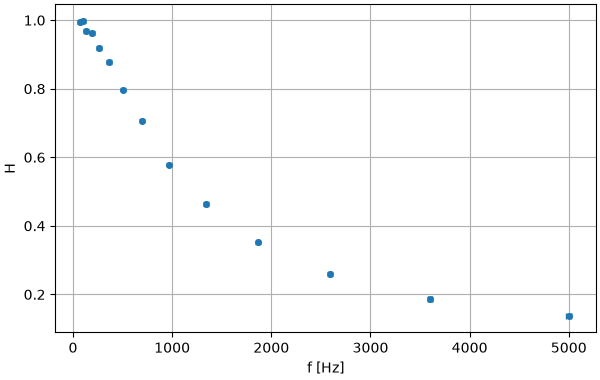

In [2]:
analysis = lab.analysis(low)
gain = analysis.make_PlotData("f [Hz]", "H", y_sigma="sigma_H", x_sigma="sigma_f [Hz]")   # error bars in x and y;
# both are optional, the fit includes them (x: effective variance), leave one out to ignore it

analysis.plot_data("lowpass_points", gain, "Measured gain of the low-pass")   # only the points

f_g = 688.5 ± 4.4
chi²/ndf = 23.7/13 = 1.83
x uncertainties included (effective variance)


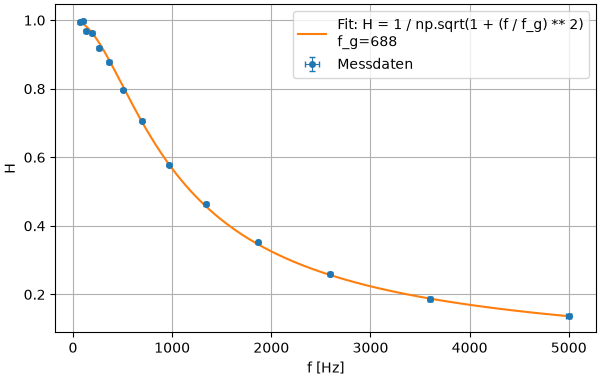

(array([688.46542379]), array([4.41347363]))

In [3]:
def lowpass(f, f_g):                       # the model: first argument x, then the parameters
    return 1 / np.sqrt(1 + (f / f_g) ** 2)

result = analysis.regression("lowpass_fit", lowpass, gain, p0=[500])   # fit + plot + report
result.values, result.errors

## Several layers in one plot: `lab.Visualize`

In [4]:
high = lab.edit_csv("data/filter/highpass.csv", name="highpass")
high.add_column("H", lambda U_a, U_e: U_a / U_e)
analysis_high = lab.analysis(high)
gain_high = analysis_high.make_PlotData("f [Hz]", "H")

def highpass(f, f_g):
    return (f / f_g) / np.sqrt(1 + (f / f_g) ** 2)

f_g = 688.5 ± 4.4
chi²/ndf = 23.7/13 = 1.83
x uncertainties included (effective variance)
f_g = 701.9 ± 3.1


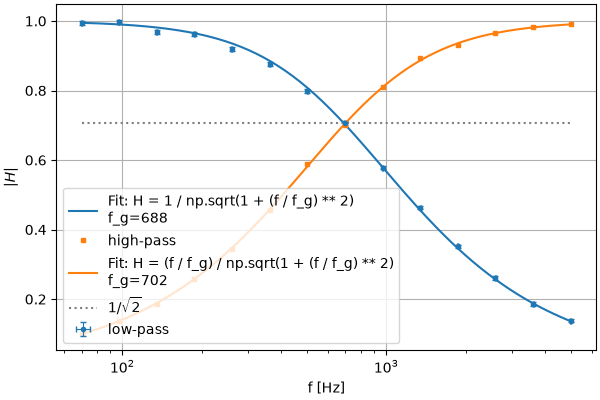

In [5]:
amplitude = lab.Visualize("amplitude", "Gain of both filters",          # becomes plots/amplitude
                          layout=LayoutStyle(xscale="log", ylabel="$|H|$"))

# data + fit curve of the low-pass; the colors are set so that points and curve belong together
amplitude.add(analysis.make_regression(lowpass, gain, p0=[500]),
              points=PointStyle(label="low-pass", marker_color="C0"), fit=FitStyle(color="C0"))

# the same for the high-pass, from another table
amplitude.add(analysis_high.make_regression(highpass, gain_high, p0=[500]),
              points=PointStyle(label="high-pass", marker="s", marker_color="C1"),
              fit=FitStyle(color="C1"))

# an analytic function (a constant is a horizontal line)
amplitude.add(lambda f: 1 / np.sqrt(2), fit=FitStyle(label="$1/\\sqrt{2}$", color="gray", linestyle=":"))
amplitude                                                               # a cell shows the plot

## Theory curve over measured phase

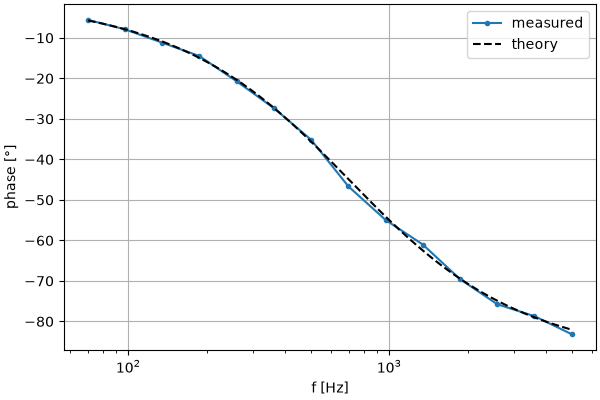

In [6]:
phase = lab.edit_csv("data/filter/phase.csv", name="phase")
phase.add_column("phase [°]", lambda Delta_t, f: -360 * Delta_t * f, show=True)
analysis_phase = lab.analysis(phase)

phase_plot = lab.Visualize("phase", layout=LayoutStyle(xscale="log"))
phase_plot.add(analysis_phase.make_PlotData("f [Hz]", "phase [°]"),
               points=PointStyle(label="measured", connect_points=True))
phase_plot.add(lambda f: -np.degrees(np.arctan(f / 700)),
               fit=FitStyle(label="theory", linestyle="--", color="k"), x=(70, 5000))
phase_plot

## Fit only a range: the slope of the flank

m = -19.33 ± 0.64
b = 54.2 ± 2.3


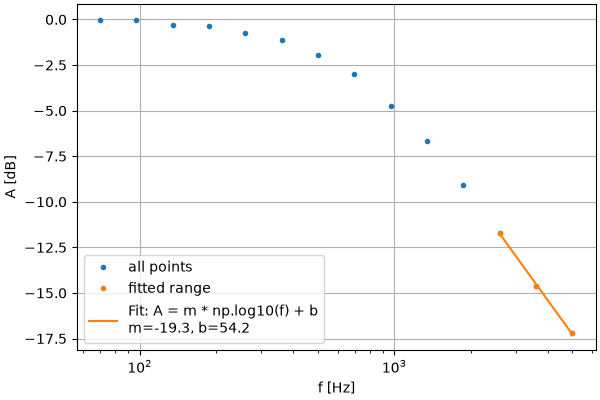

In [7]:
low.add_column("A [dB]", lambda H: 20 * np.log10(H))             # gain in dB
analysis = lab.analysis(low)                                      # (the table has a new column)

def line_in_log_f(f, m, b):                                       # straight line over log10(f)
    return m * np.log10(f) + b

everything = analysis.make_PlotData("f [Hz]", "A [dB]")
flank = analysis.make_PlotData("f [Hz]", "A [dB]", x_range=(2000, None))   # f >= 2 kHz; y_range works too

slope = lab.Visualize("flank", layout=LayoutStyle(xscale="log"))
slope.add(everything, points=PointStyle(label="all points", marker_color="C0"))
slope.add(analysis.make_regression(line_in_log_f, flank, p0=[-20, 0]),
          points=PointStyle(label="fitted range", marker_color="C1"), fit=FitStyle(color="C1"))
slope                                                              # m is the slope in dB/decade

## Styles

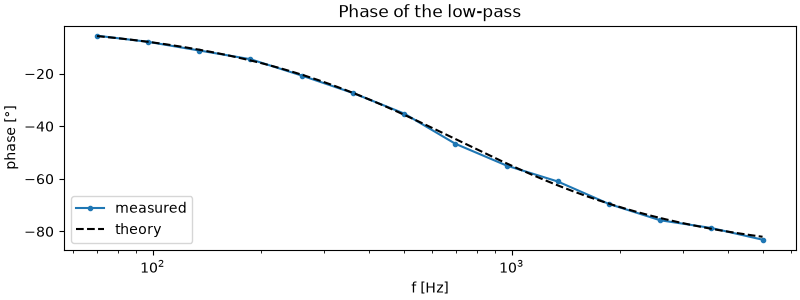

In [8]:
phase_plot.layout = replace(phase_plot.layout, figsize=(8, 3), title="Phase of the low-pass")  # a changed copy
phase_plot.layout = replace(phase_plot.layout, legend_loc="lower left", grid=False)
phase_plot

In [9]:
lab.build()
for path in sorted(Path("pemlab_build/plots").rglob("*")):
    print(path.relative_to("pemlab_build").as_posix())
print(Path("pemlab_build/plots/amplitude/amplitude.tex").read_text(encoding="utf-8"))

plots/amplitude
plots/amplitude/amplitude.pdf
plots/amplitude/amplitude.png
plots/amplitude/amplitude.tex
plots/flank
plots/flank/flank.pdf
plots/flank/flank.png
plots/flank/flank.tex
plots/lowpass_fit
plots/lowpass_fit/lowpass_fit.pdf
plots/lowpass_fit/lowpass_fit.png
plots/lowpass_fit/lowpass_fit.tex
plots/lowpass_points
plots/lowpass_points/lowpass_points.pdf
plots/lowpass_points/lowpass_points.png
plots/lowpass_points/lowpass_points.tex
plots/phase
plots/phase/phase.pdf
plots/phase/phase.png
plots/phase/phase.tex
\begin{figure}[H]
  \centering
  \includegraphics[width=0.8\textwidth]{pemlab_build/plots/amplitude/amplitude.pdf}
  \caption{Gain of both filters}
  \label{fig:amplitude}
  \par\medskip
  {\footnotesize
Regression: $H = \frac{1}{\sqrt{\frac{f^{2}}{f_{g}^{2}} + 1}}$
\par\smallskip
\begin{tabular}{lrr}
  parameter & value & error \\
  \hline
  $f_{g}$ & \num{688.5} & $\pm$ \num{4.4} \\
\end{tabular}
\par\smallskip
$\chi^2/\mathrm{ndf} = 23.7/13 = 1.83$
\par\smallskip
Uncert